# Заняття 4. Дослідницький аналіз і візуальна комунікація — стартовий ноутбук

Навчальні дані створені кодом (вигадані, не реальні продажі). Виконуйте клітинки по порядку (Shift+Enter). Перед кожним кроком **спершу передбачте результат**, потім запускайте.

Потрібні пакети: `pip install pandas numpy matplotlib seaborn plotly nbformat`.

---
**Виконала:** Наталя Шкандала  
**Запитання та аудиторія:** Яка кав'ярня продає більше напоїв, як змінюються продажі за тижнями та чи пов'язані якось денні продажі двох точок? Для власниці мережі кав'ярень без технічного бекграунду.

## Перед стартом: VS Code і Git
- Kernel → `.venv` (вгорі праворуч); у терміналі (``Ctrl+` ``) — `(.venv)`.
- Перевірка: `git --version`. Один раз: `git config --global user.name "Ім'я Прізвище"` і `git config --global user.email "you@example.com"`.
- **Source Control → Initialize Repository**; файл `.gitignore` з рядком `.venv/`.
- Перший коміт: `git add .` → `git commit -m "Заняття 4: старт"`; далі **Publish Branch** → private repository.
- Після змін: **Commit → Sync Changes**. Паролі й ключі не комітимо.

## 0. Дані
Запустіть клітинку: вона створює таблиці `sales` (продажі) і `prices` (довідник цін).

In [1]:
import pandas as pd
import numpy as np

dates = pd.date_range("2026-09-01", periods=56, freq="D")
rows = []
for i, d in enumerate(dates):
    for shop in ["Центр", "Лівий берег"]:
        for drink in ["Еспресо", "Капучино", "Лате"]:
            base = {"Еспресо": 30, "Капучино": 22, "Лате": 18}[drink]
            bonus = 8 if shop == "Центр" else 0
            weekend = 6 if d.dayofweek >= 5 else 0
            cups = base + bonus + weekend + (i // 7) + (i * 7 + len(drink)) % 5 + (i * 5 + len(shop) * 3) % 4
            rows.append([d, shop, drink, cups])
sales = pd.DataFrame(rows, columns=["date", "shop", "drink", "cups"])
prices = pd.DataFrame({"drink": ["Еспресо", "Капучино", "Лате"], "price": [60, 85, 95]})

print(sales.shape)
print(sales.head(3))


(336, 4)
        date   shop     drink  cups
0 2026-09-01  Центр   Еспресо    43
1 2026-09-01  Центр  Капучино    36
2 2026-09-01  Центр      Лате    33


## 1. GroupBy і зведена таблиця
Запитання: яка точка і який напій дають найбільше чашок?
Підказка: `sales.groupby("shop")["cups"].sum()`, `sales.pivot_table(index="drink", columns="shop", values="cups", aggfunc="sum")`.

In [2]:
# ваш код тут

#**Передбачення:** очікую, що точка «Центр» продала більше чашок, ніж «Лівий берег», а найпопулярнішим напоєм є Капучино.

#**Що робимо на цьому кроці:**
#1. Групуємо продажі за кав'ярнею (`groupby`), щоб порівняти загальну кількість проданих чашок.
#2. Групуємо за кав'ярнею та напоєм одночасно (`agg`), щоб побачити суму та середнє значення на день.
#3. Будуємо зведену таблицю (`pivot_table`), щоб порівняти напої між точками в зручному форматі.

# 1. Загальна сума проданих чашок по кожній кав'ярні (групуємо)
print("=== 1. Сума чашок за точками ===")
print(sales.groupby("shop")["cups"].sum())

# 2. Групуємо за точкою і напоєм (сума і середнє)
print("\n=== 2. Сума та середнє за точкою i напоєм ===")
print(sales.groupby(["shop", "drink"])["cups"].agg(["sum", "mean"]).round(1))

# 3. Зведена таблиця (pivot_table): напої в рядках, точки в колонках
print("\n=== 3. Зведена таблиця продажів ===")
pivot = sales.pivot_table(index="drink", columns="shop", values="cups", aggfunc="sum")
print(pivot)

=== 1. Сума чашок за точками ===
shop
Лівий берег    5387
Центр          6731
Name: cups, dtype: int64

=== 2. Сума та середнє за точкою i напоєм ===
                       sum  mean
shop        drink               
Лівий берег Еспресо   2168  38.7
            Капучино  1721  30.7
            Лате      1498  26.8
Центр       Еспресо   2616  46.7
            Капучино  2169  38.7
            Лате      1946  34.8

=== 3. Зведена таблиця продажів ===
shop      Лівий берег  Центр
drink                       
Еспресо          2168   2616
Капучино         1721   2169
Лате             1498   1946


## 2. Об’єднання з цінами і перевірки (assert)
Підказка: `sales.merge(prices, on="drink", how="left")`; додайте assert на кількість рядків, пропуски і суму.

In [3]:
# ваш код тут
# 1. Запам'ятовуємо кількість рядків до об'єднання та з'єднуємо таблиці за колонкою drink
rows_before = len(sales)
full = sales.merge(prices, on="drink", how="left")

# 2. Перевірки assert (контролер мовчить, якщо все гаразд)
assert len(full) == rows_before, "join змінив кількість рядків"
assert full["price"].notna().all(), "є напої без ціни"
print("перевірки пройдено")

# 3. Рахуємо виторг (cups * price)
full["revenue"] = full["cups"] * full["price"]
print("Загальний виторг:", full["revenue"].sum())
print(full.groupby("shop")["revenue"].sum())

перевірки пройдено
Загальний виторг: 944870
shop
Лівий берег    418675
Центр          526195
Name: revenue, dtype: int64


## 3. Розподіл
`describe()`, середнє й медіана, гістограма (`plt.hist`) і boxplot (`sns.boxplot`).

=== Описова статистика cups ===
count    336.0
mean      36.1
std        7.5
min       18.0
25%       30.0
50%       36.0
75%       41.0
max       55.0
Name: cups, dtype: float64

Середне (mean): 36.1
Медіана (median): 36.0


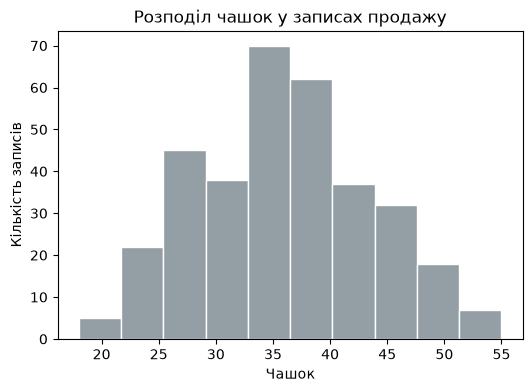

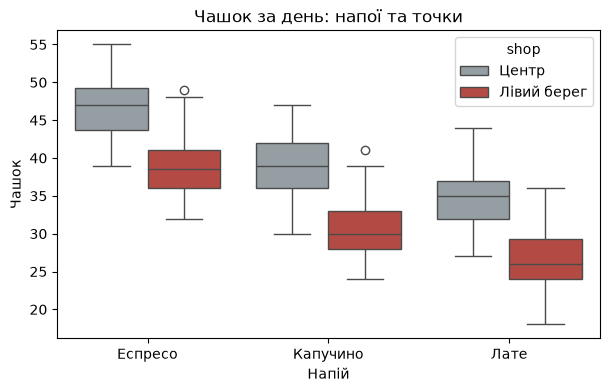

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# ваш код тут

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Паспорт колонки cups (describe)
print("=== Описова статистика cups ===")
print(full["cups"].describe().round(1))

# 2. Порівняння середнього та медіани
print("\nСередне (mean):", round(full["cups"].mean(), 1))
print("Медіана (median):", full["cups"].median())

# 3. Гістограма розподілу чашок
plt.figure(figsize=(6, 4))
plt.hist(full["cups"], bins=10, color="#939FA5", edgecolor="white")
plt.title("Розподіл чашок у записах продажу")
plt.xlabel("Чашок")
plt.ylabel("Кількість записів")
plt.show()

# 4. Boxplot за напоями і точками
plt.figure(figsize=(7, 4))
sns.boxplot(data=full, x="drink", y="cups", hue="shop", palette=["#939FA5", "#C63B31"])
plt.title("Чашок за день: напої та точки")
plt.xlabel("Напій")
plt.ylabel("Чашок")
plt.show()


## 4. Діаграми: категорії, час, зв’язок
Стовпчики від нуля, лінія за тижнями (`pd.Grouper(key="date", freq="W")`), scatter для двох показників. Заголовки й підписи осей — обов’язково.

**Яке запитання — така діаграма:** зміна в часі → лінія · порівняння → стовпчики від нуля · рейтинг → впорядковані стовпчики · частка й ціле → складені стовпчики · зв’язок → scatter · розподіл → гістограма або boxplot.

**Як прочитати scatter — 4 запитання:** 1) що на осях? 2) що означає одна точка? 3) що ми очікуємо побачити? 4) де дані відхиляються від очікування? → це і є історія.

Після свого scatter дайте письмові відповіді на ці 4 запитання:
1. Що на осях: На горизонтальній осі — продажі на «Лівому березі», на вертикальній — у «Центрі» (у чашках за день).
2. Що означає одна точка: Один день із нашого періоду
3. Що ми очікуємо побачити: Якщо точки йдуть вгору й праворуч — значить, кав'ярні працюють синхронно (і роблять свої продажі досить гарно).
4. Де дані відхиляються від очікування: Є невеликі відхилення в окремі дні, але загалом зв'язок прямий і дуже сильний (кореляція 0.86).

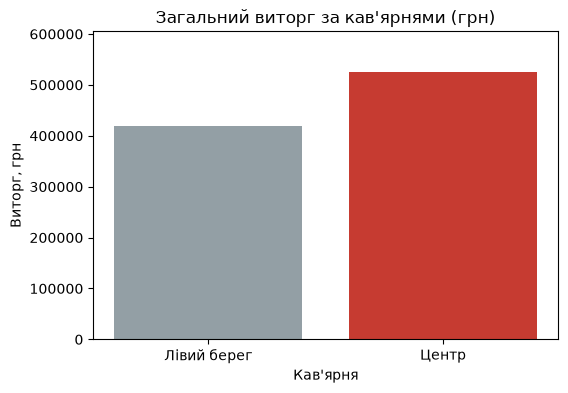

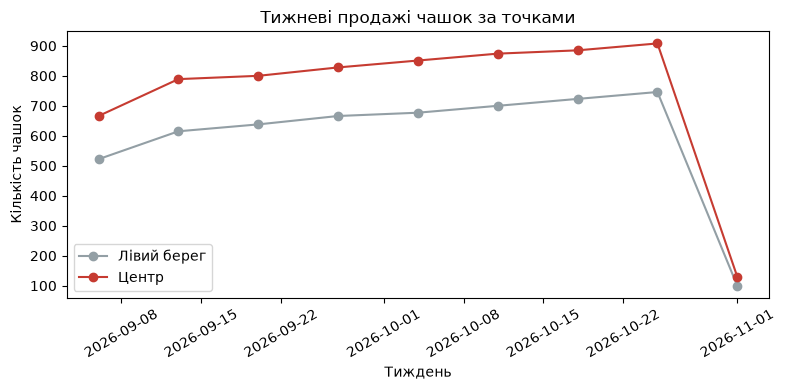

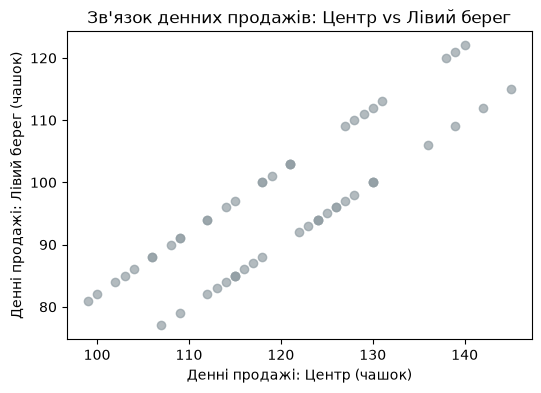

In [5]:
# ваш код тут

# 1. Стовпчики від нуля: порівняння виторгу за точками
by_shop = full.groupby("shop")["revenue"].sum()

plt.figure(figsize=(6, 4))
plt.bar(by_shop.index, by_shop.values, color=["#939FA5", "#C63B31"])
plt.ylim(0, by_shop.max() * 1.15)  # вісь обов'язково від нуля
plt.title("Загальний виторг за кав'ярнями (грн)")
plt.xlabel("Кав'ярня")
plt.ylabel("Виторг, грн")
plt.show()

# 2. Лінія за тижнями: динаміка продажів у часі
weekly = full.groupby([pd.Grouper(key="date", freq="W"), "shop"])["cups"].sum().unstack()

plt.figure(figsize=(8, 4))
for shop, color in zip(weekly.columns, ["#939FA5", "#C63B31"]):
    plt.plot(weekly.index, weekly[shop], marker="o", label=shop, color=color)
plt.title("Тижневі продажі чашок за точками")
plt.xlabel("Тиждень")
plt.ylabel("Кількість чашок")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# 3. Scatter: зв'язок денних продажів двох точок
daily_shops = full.pivot_table(index="date", columns="shop", values="cups", aggfunc="sum")

plt.figure(figsize=(6, 4))
plt.scatter(daily_shops["Центр"], daily_shops["Лівий берег"], color="#939FA5", alpha=0.7)
plt.title("Зв'язок денних продажів: Центр vs Лівий берег")
plt.xlabel("Денні продажі: Центр (чашок)")
plt.ylabel("Денні продажі: Лівий берег (чашок)")
plt.show()


### Для першої діаграми (виторг/продажі за кав'ярнями):
«Точка „Центр“ є лідером за загальним обсягом проданих напоїв та виторгом порівняно з точкою „Лівий берег“»

### Для другої діаграми (динаміка продажів за тижнями):
«Продажі в обох кав'ярнях показують стабільну динаміку із синхронним зростанням попиту у вихідні дні що є нормальною тенденцією»

### Для третьої діаграми (денні продажі / кореляція):
«Існує тісний зв'язок між денними продажами обох точок, що вказує на спільний вплив певних зовнішніх факторів на покупців»

## 5. Візуальна історія
**Запитання:** Чи справдилось моє попереднє передбачення, яка кав'ярня продає більше напоїв, як змінюються продажі за тижнями та чи пов'язані якось денні продажі двох точок?  
**Аудиторія:** Власниця мережі кав'ярень без технічного бекграунду.

* **Висновок 1: Моє попереднє передбачення не справдилось.** Продажі показали, що лідує все ж такі еспрессо, а не капучіно. 
* **Висновок 2: Точка «Центр» є лідером за продажами та виторгом.** Вона продала більше чашок майже на 25% і принесла більше прибутку порівняно з «Лівим берегом».  
  * *Діаграма:* Стовпчкова діаграма загального виторгу за кав'ярнями (від нуля).
* **Висновок 3: Продажі стабільні з невеликими коливаннями по тижнях (що можна вважати нормальним).** Динаміка показує синхронне зростання попиту в обидвох точках, причому вихідні дні традиційно додають обертів.  
  * *Діаграма:* Лінійний графік тижневих продажів у чашках за точками (`pd.Grouper`).
* **Висновок 4: Денні продажі двох точок тісно пов'язані.** Коли гарний день у «Центрі», «Лівий берег» зазвичай теж продає більше (кореляція ~0.86), що свідчить про загальні зовнішні фактори (наприклад, погоду чи дні тижня).  
  * *Діаграма:* Діаграма розсіювання (Scatter plot) денних продажів (Центр vs Лівий берег). 

**Обмеження:** Дані вигадані (створені програмно), тому висновки мають демонстраційний характер і не враховують сезонність реального бізнесу або витрати на оренду й зарплату.

## Для AI відправила запитання щодо кольорів: чи буде ок для графіків у ДЗ обрати саме таку палітру кольорів (["#939FA5", "#C63B31"]) щоб досягти мети завдання? Чи буде краще обрати інші кольори?

Відповідь: Нейтральний сірий та акцентний червоний кольори використано для того, щоб наочно виділити головного лідера (кав'ярню з більшим виторгом) і зробити візуалізацію максимально інтуїтивною для бізнес-аудиторії без технічної підготовки. 

Залишила такі кольори.

In [6]:
# ваш код тут
